In [9]:
import boto3

s3 = boto3.client("s3")

BUCKET_NAME = "covid19-xray"

In [13]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [15]:
import tensorflow as tf
print(tf.__version__)

2.21.0


In [18]:
import os

print(os.getcwd())

/home/ec2-user/SageMaker


In [19]:
LOCAL_DATASET = "./covid19_dataset"

os.makedirs(LOCAL_DATASET, exist_ok=True)

print("Dataset folder:", os.path.abspath(LOCAL_DATASET))

Dataset folder: /home/ec2-user/SageMaker/covid19_dataset


In [20]:
!aws s3 cp s3://covid19-xray/train/ ./covid19_dataset/train/ --recursive

fatal error: Unable to locate credentials


In [21]:
!aws s3 cp s3://covid19-xray/test/ ./covid19_dataset/test/ --recursive

fatal error: Unable to locate credentials


In [22]:
!aws s3 cp s3://covid19-xray/test/ ./covid19_dataset/test/ --recursive

fatal error: Unable to locate credentials


In [23]:
!find ./covid19_dataset -maxdepth 2 -type d

./covid19_dataset
./covid19_dataset/train
./covid19_dataset/train/Viral Pneumonia
./covid19_dataset/train/Normal
./covid19_dataset/train/Covid
./covid19_dataset/test
./covid19_dataset/test/Viral Pneumonia
./covid19_dataset/test/Normal
./covid19_dataset/test/Covid


In [24]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 16

train_dir = "./covid19_dataset/train"
test_dir = "./covid19_dataset/test"

In [25]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset="training",
    seed=42,
    label_mode="categorical"
)

Found 251 files belonging to 3 classes.
Using 201 files for training.


E0000 00:00:1791481570.773925  656737 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


In [26]:
validation_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset="validation",
    seed=42,
    label_mode="categorical"
)

Found 251 files belonging to 3 classes.
Using 50 files for validation.


In [27]:
test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    label_mode="categorical"
)

Found 66 files belonging to 3 classes.


In [28]:
print("Classes:", train_dataset.class_names)

Classes: ['Covid', 'Normal', 'Viral Pneumonia']


In [29]:
!pip install matplotlib

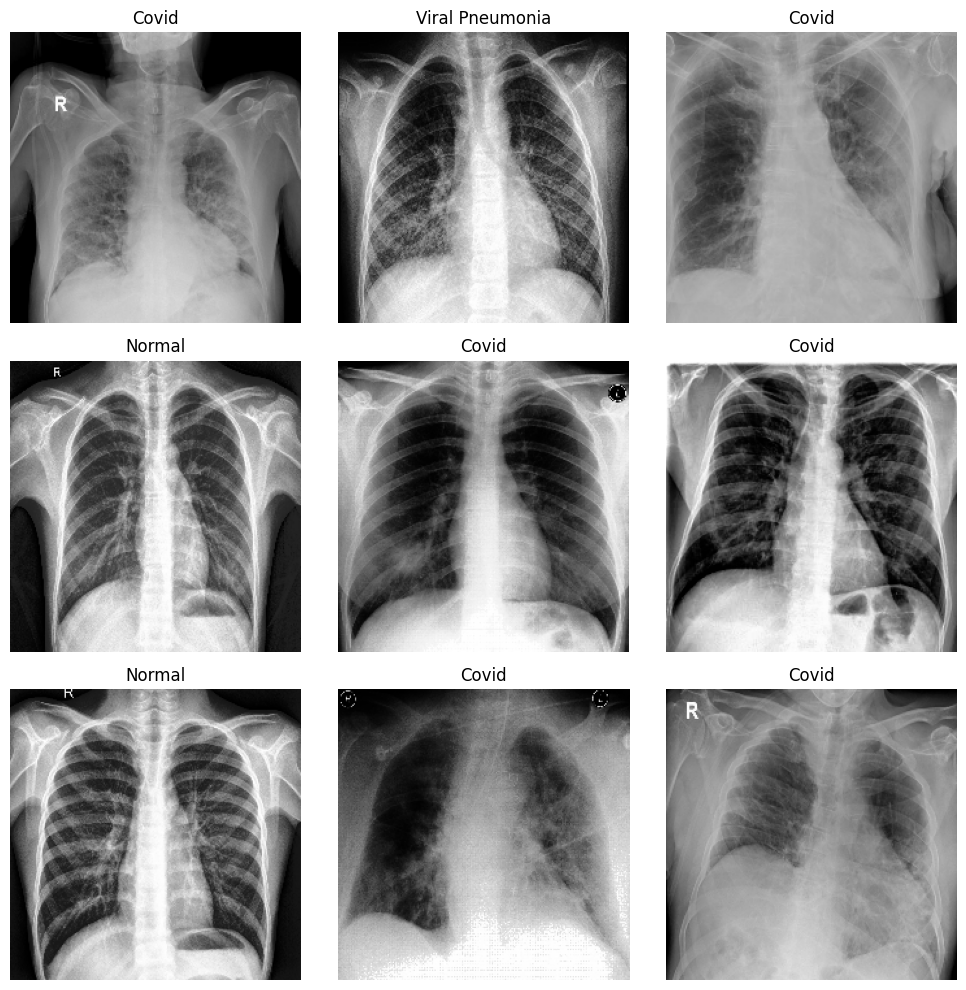

In [30]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 10))

for images, labels in train_dataset.take(1):
    for i in range(min(9, len(images))):
        ax = plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(train_dataset.class_names[np.argmax(labels[i].numpy())])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [32]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10),
], name="data_augmentation")

In [33]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.prefetch(buffer_size=AUTOTUNE)

In [35]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 8

In [36]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset="training",
    seed=42,
    label_mode="categorical"
)

Found 251 files belonging to 3 classes.
Using 201 files for training.


In [37]:
validation_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset="validation",
    seed=42,
    label_mode="categorical"
)

Found 251 files belonging to 3 classes.
Using 50 files for validation.


In [38]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(AUTOTUNE)
validation_dataset = validation_dataset.prefetch(AUTOTUNE)
test_dataset = test_dataset.prefetch(AUTOTUNE)

In [40]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10),
], name="data_augmentation_128")

In [41]:
model = tf.keras.Sequential([
    
    tf.keras.layers.Input(shape=(128, 128, 3)),
    
    data_augmentation,
    
    tf.keras.layers.Rescaling(1./255),
    
    tf.keras.layers.Conv2D(16, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    
    tf.keras.layers.GlobalAveragePooling2D(),
    
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.5),
    
    tf.keras.layers.Dense(3, activation="softmax")
])

In [42]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [43]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation_128           │ (None, 128, 128, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 126, 126, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 63, 63, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 61, 61, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 28, 28, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,939 (109.14 KB)

 Trainable params: 27,939 (109.14 KB)

 Non-trainable params: 0 (0.00 B)

In [44]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [45]:
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=15,
    callbacks=[early_stopping]
)

Epoch 1/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 8s 219ms/step - accuracy: 0.3582 - loss: 1.1008 - val_accuracy: 0.4400 - val_loss: 1.0820
Epoch 2/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 11s 238ms/step - accuracy: 0.4378 - loss: 1.0837 - val_accuracy: 0.4400 - val_loss: 1.0763
Epoch 3/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 10s 257ms/step - accuracy: 0.3731 - loss: 1.0944 - val_accuracy: 0.4400 - val_loss: 1.0804
Epoch 4/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 9s 211ms/step - accuracy: 0.4577 - loss: 1.0746 - val_accuracy: 0.5200 - val_loss: 1.0552
Epoch 5/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 10s 211ms/step - accuracy: 0.4876 - loss: 1.0409 - val_accuracy: 0.5200 - val_loss: 0.9835
Epoch 6/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 10s 208ms/step - accuracy: 0.4925 - loss: 1.0529 - val_accuracy: 0.5000 - val_loss: 0.9942
Epoch 7/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 5s 206ms/step - accuracy: 0.5622 - loss: 0.9897 - val_accuracy: 0.4200 - val_loss: 1.0496
Epoch 8/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 11s 248ms/step - accuracy: 0.5373 - loss: 0.9430 - val_accurac

In [47]:
test_loss, test_accuracy = model.evaluate(test_dataset)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", test_accuracy * 100)

5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 187ms/step - accuracy: 0.6667 - loss: 0.8326
Test Loss: 0.8325932621955872
Test Accuracy: 0.6666666865348816
Test Accuracy (%): 66.66666865348816


In [48]:
import numpy as np

y_true = []
y_pred = []

for images, labels in test_dataset:
    predictions = model.predict(images, verbose=0)
    
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Actual labels:", len(y_true))
print("Predicted labels:", len(y_pred))

Actual labels: 66
Predicted labels: 66


In [50]:
import numpy as np

num_classes = 3

cm = np.zeros((num_classes, num_classes), dtype=int)

for actual, predicted in zip(y_true, y_pred):
    cm[actual, predicted] += 1

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[26  0  0]
 [ 4 16  0]
 [11  7  2]]


In [51]:
class_names = ["Covid", "Normal", "Viral Pneumonia"]

for i, class_name in enumerate(class_names):
    
    true_positive = cm[i, i]
    false_positive = cm[:, i].sum() - true_positive
    false_negative = cm[i, :].sum() - true_positive
    
    precision = (
        true_positive / (true_positive + false_positive)
        if (true_positive + false_positive) > 0 else 0
    )
    
    recall = (
        true_positive / (true_positive + false_negative)
        if (true_positive + false_negative) > 0 else 0
    )
    
    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0 else 0
    )
    
    print(f"\n{class_name}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-score:  {f1:.4f}")


Covid
Precision: 0.6341
Recall:    1.0000
F1-score:  0.7761

Normal
Precision: 0.6957
Recall:    0.8000
F1-score:  0.7442

Viral Pneumonia
Precision: 1.0000
Recall:    0.1000
F1-score:  0.1818


In [52]:
accuracy = np.trace(cm) / np.sum(cm)

print(f"Overall Test Accuracy: {accuracy:.4f}")
print(f"Overall Test Accuracy: {accuracy * 100:.2f}%")

Overall Test Accuracy: 0.6667
Overall Test Accuracy: 66.67%


In [55]:
MODEL_PATH = "./covid19_model.keras"

model.save(MODEL_PATH)

print("Model saved successfully!")

Model saved successfully!


In [56]:
import os

print("File exists:", os.path.exists(MODEL_PATH))
print("File size:", os.path.getsize(MODEL_PATH) / 1024, "KB")

File exists: True
File size: 386.287109375 KB


In [57]:
import tensorflow as tf

loaded_model = tf.keras.models.load_model("./covid19_model.keras")

print("Saved model loaded successfully!")

Saved model loaded successfully!


In [58]:
test_loss, test_accuracy = loaded_model.evaluate(test_dataset)

print("Loaded Model Test Accuracy:", test_accuracy)
print("Loaded Model Test Accuracy: {:.2f}%".format(test_accuracy * 100))

5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 171ms/step - accuracy: 0.6667 - loss: 0.8326
Loaded Model Test Accuracy: 0.6666666865348816
Loaded Model Test Accuracy: 66.67%


In [60]:
import numpy as np
from tensorflow.keras.utils import load_img, img_to_array

def predict_xray(image_path):
    img = load_img(image_path, target_size=(128, 128))
    img_array = img_to_array(img)

    img_array = np.expand_dims(img_array, axis=0)
    img_array = img_array / 255.0

    predictions = loaded_model.predict(img_array, verbose=0)

    predicted_class = np.argmax(predictions[0])
    confidence = predictions[0][predicted_class]

    return class_names[predicted_class], confidence

In [61]:
import glob

sample_images = glob.glob("./covid19_dataset/test/Covid/*")

print(sample_images[0])

./covid19_dataset/test/Covid/0120.jpg


In [62]:
result, confidence = predict_xray(sample_images[0])

print("Prediction:", result)
print("Confidence: {:.2f}%".format(confidence * 100))

Prediction: Viral Pneumonia
Confidence: 50.62%
